# Experiment 2: Stability, correctness and class-specific responses
## All 3,421 test images; seed 42; three noise realizations; run-1 ResNet18 224, ResNet50 28 and original ViT

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

seed, batch_size = 42, 32
torch.manual_seed(seed)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
output = Path('predictions/stability.npz')
output.parent.mkdir(exist_ok=True)
print(device)
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))

cuda


## Ten non-identity levels per operation — translation in subpixels, noise σ on [0, 1], blur radius in pixels

In [2]:
levels = {
    'rotation': np.linspace(-20, 20, 10),
    'translation': np.linspace(-3, 3, 10),
    'brightness': np.linspace(0.8, 1.2, 10),
    'blur': np.linspace(0.15, 1.5, 10),
    'noise': np.linspace(0.01, 0.1, 10),
    'green_scale': np.linspace(0.9, 1.1, 10),
    'red_scale': np.linspace(0.9, 1.1, 10),
    'blue_scale': np.linspace(0.9, 1.1, 10),
}
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    test_images = data['test_images']
    test_labels = data['test_labels'].ravel()
indices = np.arange(len(test_images))
images, labels = test_images[indices], test_labels[indices]
baseline = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)[indices]
    np.testing.assert_array_equal(rows[:, 0], indices)
    np.testing.assert_array_equal(rows[:, 1], labels)
    baseline.append(rows[:, 3:])
baseline = np.stack(baseline)
base_class = baseline.argmax(-1)
all_correct = (base_class == labels).all(axis=0)
print(f'{len(images)} images; {all_correct.sum()} initially correct for all models')

3421 images; 3191 initially correct for all models


## Transform original 28 × 28 RGB images — shared inputs for all models, gray borders, no wraparound

Noise seeds use the original test index, severity and repeat. The previous subset experiment used subset positions, so the full-population noise realizations follow a new explicit seed protocol.

In [3]:
def transform(images, kind, level, repeat=0):
    result = []
    for i, image in enumerate(images):
        pil = Image.fromarray(image)
        if kind == 'rotation':
            changed = pil.rotate(float(level), resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'translation':
            changed = pil.transform(pil.size, Image.Transform.AFFINE, (1, 0, -float(level), 0, 1, 0),
                                    resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'brightness':
            changed = ImageEnhance.Brightness(pil).enhance(float(level))
        elif kind == 'blur':
            changed = pil.filter(ImageFilter.GaussianBlur(float(level)))
        elif kind == 'noise':
            key = f'{seed}:{i}:{level}:{repeat}'
            noise_seed = int.from_bytes(hashlib.sha256(key.encode()).digest()[:8], 'little')
            noise = np.random.default_rng(noise_seed).normal(0, level, image.shape)
            changed = np.rint(np.clip(image / 255.0 + noise, 0, 1) * 255).astype(np.uint8)
        else:
            channel = {'red_scale': 0, 'green_scale': 1, 'blue_scale': 2}[kind]
            changed = image.astype(float)
            changed[..., channel] *= level
            changed = np.rint(np.clip(changed, 0, 255)).astype(np.uint8)
        result.append(np.asarray(changed))
    return np.stack(result)

## Load models and predict in batches

In [4]:
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

baseline_logits = [np.load(f'predictions/{name}_test.npz')['logits'][indices] for name in model_names]
gate = np.concatenate([np.flatnonzero(labels == c)[:8] for c in range(8)])
for m in range(len(models)):
    np.testing.assert_allclose(predict(m, images[gate])[0], baseline[m, gate], atol=1e-5, rtol=1e-4)


## Run experiment and save full probabilities and raw logits — model × level × realization × image × class

In [5]:
from numpy.lib.format import open_memmap

files = [*checkpoints[:2], 'models/vit/model.safetensors', 'models/vit/config.json', 'models/vit/preprocessor_config.json']
weight_hashes = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in files]
signature = hashlib.sha256(images.tobytes() + labels.tobytes() + baseline.tobytes()
                           + str(weight_hashes).encode() + str(levels).encode() + str(seed).encode() + b'test-index-noise-v2').hexdigest()
if output.exists():
    with np.load(output, allow_pickle=False) as saved:
        assert str(saved['signature']) == signature, 'Saved experiment differs from current inputs.'
    print(f'Using validated full-test cache: {output}')
else:
    cache = Path('outputs/stability_test_v2')
    cache.mkdir(parents=True, exist_ok=True)
    lock = cache / 'signature.txt'
    assert not lock.exists() or lock.read_text() == signature, 'Inputs changed: use a new cache directory.'
    lock.write_text(signature)
    probabilities, logits = {}, {}
    for kind, values in levels.items():
        repeats = 3 if kind == 'noise' else 1
        arrays = []
        for suffix, shape, dtype in [('p', (3, 10, repeats, len(images), 8), 'float32'),
                                      ('logits', (3, 10, repeats, len(images), 8), 'float32'),
                                      ('done', (3, 10, repeats), 'bool')]:
            path = cache / f'{kind}_{suffix}.npy'
            fresh = not path.exists()
            a = open_memmap(path, mode='w+' if fresh else 'r+', dtype=dtype, shape=shape)
            if fresh and dtype == 'bool':
                a[:] = False
                a.flush()
            arrays.append(a)
        p, scores, done = arrays
        for j, level in enumerate(values):
            for repeat in range(repeats):
                if done[:, j, repeat].all():
                    continue
                changed = transform(images, kind, level, repeat)
                for m in range(len(models)):
                    if not done[m, j, repeat]:
                        p[m, j, repeat], scores[m, j, repeat] = predict(m, changed)
                        p.flush()
                        scores.flush()
                        done[m, j, repeat] = True
                        done.flush()
        probabilities[kind], logits[kind] = p, scores
        print(f'{kind}: all {len(images)} test images, {len(values)} levels, {repeats} realizations completed')
    np.savez_compressed(output, **probabilities, baseline=baseline, indices=indices, labels=labels,
                        seed=seed, model_names=model_names, class_names=class_names, signature=signature,
                        checkpoints=checkpoints, weight_hashes=weight_hashes, model_input_resolutions=[224,28,224],
                        baseline_logits=np.stack(baseline_logits), split='test', noise_seed_scope='original test index',
                        axes=['model','level','realization','image','class'], border_fill_rgb=[128]*3, input_shape=[28,28,3],
                        **{f'logits_{kind}': scores for kind, scores in logits.items()},
                        **{f'levels_{kind}': values for kind, values in levels.items()})
    print(output)


Using validated full-test cache: predictions\stability.npz


## Load saved results — average noise realizations within each image, not as independent images

In [6]:
with np.load(output, allow_pickle=False) as saved:
    levels = {kind: saved[f'levels_{kind}'] for kind in levels}
    probabilities = {kind: saved[kind] for kind in levels}
    baseline, indices, labels = saved['baseline'], saved['indices'], saved['labels']
    model_names = saved['model_names'].tolist()
    seed = int(saved['seed'])
images = test_images[indices]
base_class = baseline.argmax(-1)
base_probability = np.take_along_axis(baseline, base_class[..., None], axis=-1)[..., 0]
all_correct = (base_class == labels).all(axis=0)
metrics = {}
for kind, p in probabilities.items():
    predicted = p.argmax(-1)
    target = np.broadcast_to(base_class[:, None, None, :, None], p.shape[:-1] + (1,))
    retained = np.take_along_axis(p, target, axis=-1)[..., 0].mean(axis=2)
    correct = (predicted == labels).mean(axis=2)
    metrics[kind] = {
        'Change in p(original class)': retained - base_probability[:, None, :],
        'Label flip fraction': (predicted != base_class[:, None, None, :]).mean(axis=2),
        'Accuracy (all images)': correct,
        'Correct-label retention (all initially correct)': correct[:, :, all_correct],
        'Correct → wrong': (1 - correct) * (base_class == labels)[:, None, :],
        'Wrong → correct': correct * (base_class != labels)[:, None, :],
    }

## 2A — Stability and correctness: ten points per operation; dashed lines mark unmodified references

In [7]:
def plot_stability(kind, values):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.5), layout='constrained')
    reference = 1 if kind in ('brightness', 'green_scale', 'red_scale', 'blue_scale') else 0
    for ax, title in zip(axes, list(metrics[kind])[:4]):
        for m, name in enumerate(model_names):
            data = metrics[kind][title][m]
            y = data.mean(axis=-1) if data.shape[-1] else np.full(10, np.nan)
            line, = ax.plot(values, y, 'o-', label=name)
            base = (base_class[m] == labels).mean() if title.startswith('Accuracy') else (1 if title.startswith('Correct-label') else 0)
            ax.axhline(base, color=line.get_color(), ls='--', alpha=0.35)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        if not title.startswith('Change'):
            ax.set_ylim(-0.03, 1.03)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(labels)} · shared correct subset N={all_correct.sum()}')
    plt.show()

All 3,421 test images are used; the shared initially-correct comparison contains 3,191 images. Original-class probability measures support for a fixed decision, flips measure changes in class identity, and accuracy measures agreement with the recorded label. Shared-correct retention checks whether model differences persist when the starting predictions are all correct.

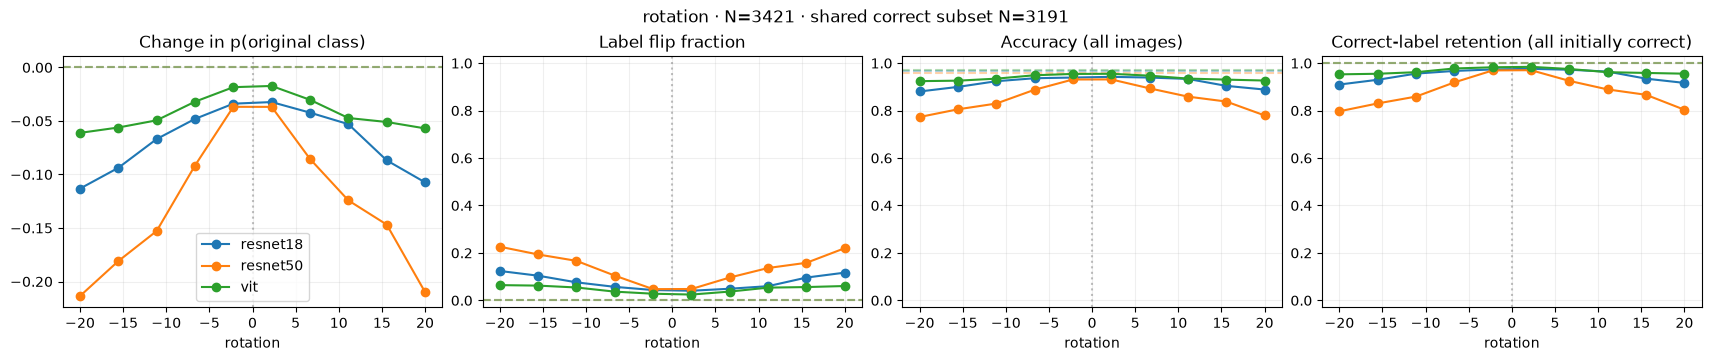

In [8]:
plot_stability('rotation', levels['rotation'])

Rotation changes 14.0% of ResNet50 decisions, compared with 7.7% for ResNet18 and 4.8% for ViT. The class analysis localizes a large part of ResNet50’s sensitivity to basophils: their mean original-class probability loss is 0.70, rather than a uniform loss across cell classes. This points to a class-dependent geometric weakness of this checkpoint, with interpolation and border changes included in the intervention.

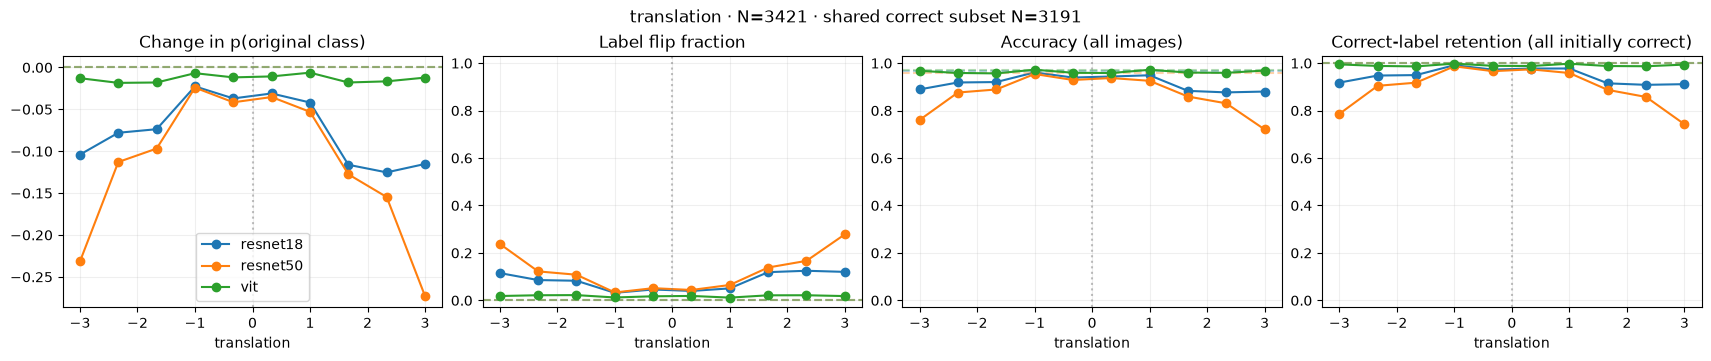

In [9]:
plot_stability('translation', levels['translation'])

ResNet50 accuracy falls to 76.0% and 72.1% at the two extreme shifts, while ViT remains at 96.8% and 96.9%. Both shift directions affect the CNN, so the result is not explained by one anomalous endpoint. The individual sequences below show that responses can also be non-monotonic, which a single maximum-shift test would miss.

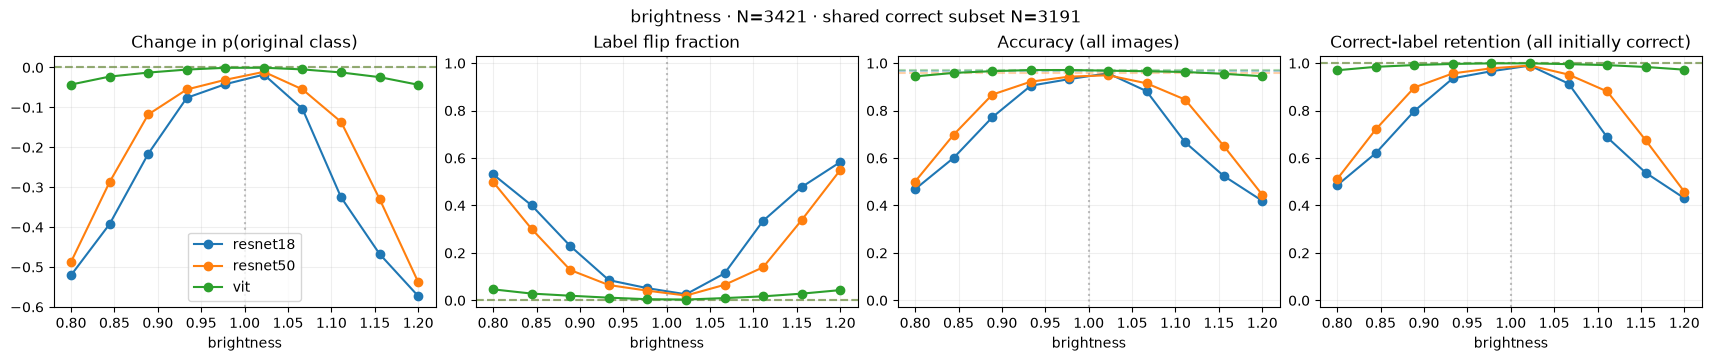

In [10]:
plot_stability('brightness', levels['brightness'])

Mean accuracy under brightness changes is 71.3% for ResNet18, 77.4% for ResNet50 and 96.1% for ViT. These are identical spatial inputs with a changed RGB gain, so the CNN losses expose dependence on appearance rather than displacement of image structures. The class fingerprint shows that this dependence is strongest for particular classes, especially monocytes, rather than equally distributed over the test set.

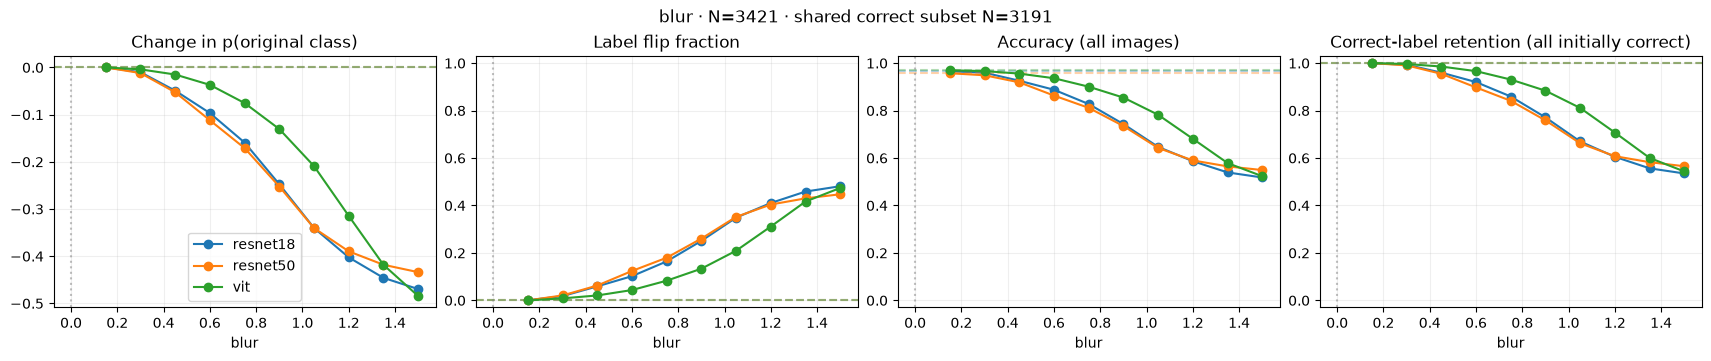

In [11]:
plot_stability('blur', levels['blur'])

ViT’s advantage at moderate blur does not persist at the strongest level: accuracy at radius 1.5 is 52.3%, versus 51.8% and 54.9% for the CNNs. This contrasts with its strong tolerance to noise and brightness, showing that the tested robustness is specific to the intervention. Blur progressively removes spatial detail, whereas noise perturbs it without the same systematic smoothing.

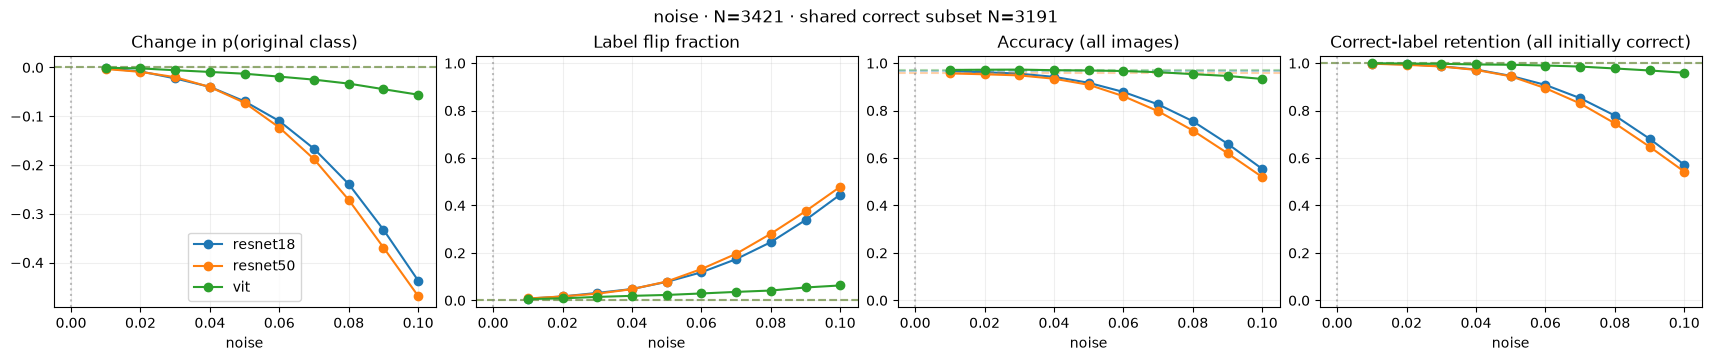

In [12]:
plot_stability('noise', levels['noise'])

At noise σ=0.1, accuracy is 55.4% for ResNet18, 52.0% for ResNet50 and 93.3% for ViT. Together with the blur result, this separates tolerance to added random variation from tolerance to removal of spatial detail. Noise realizations are averaged within each image; the biological sample remains 3,421 images, not three times that number.

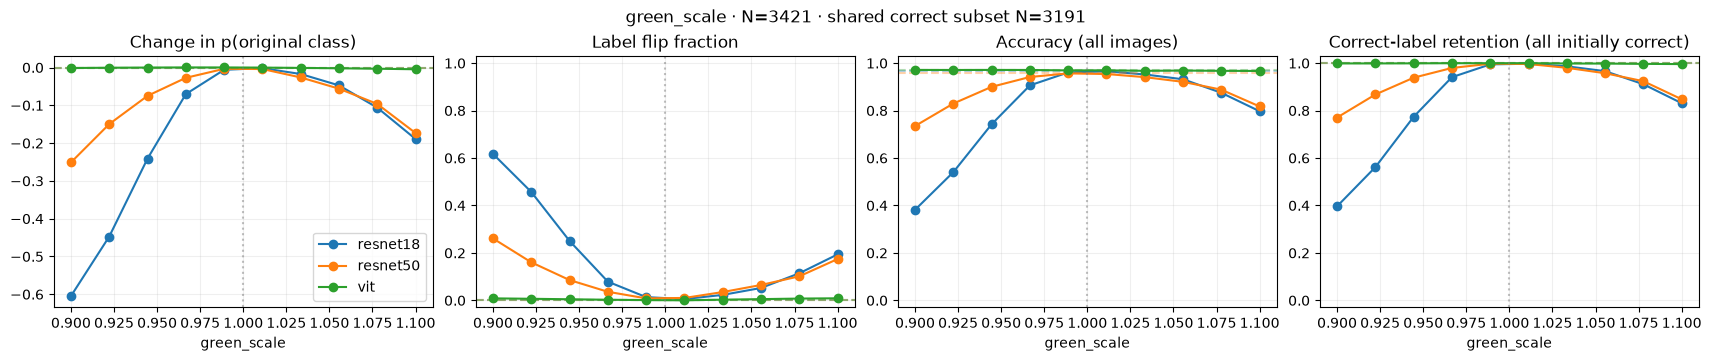

In [13]:
plot_stability('green_scale', levels['green_scale'])

ResNet18 accuracy is 38.2% when green is scaled by 0.9, but 79.7% at 1.1. Its response depends strongly on the direction of the color change, not just distance from the original image. The weaker blue-channel response and different ResNet50 profile suggest sensitivity to color balance rather than one uniform response to all RGB changes.

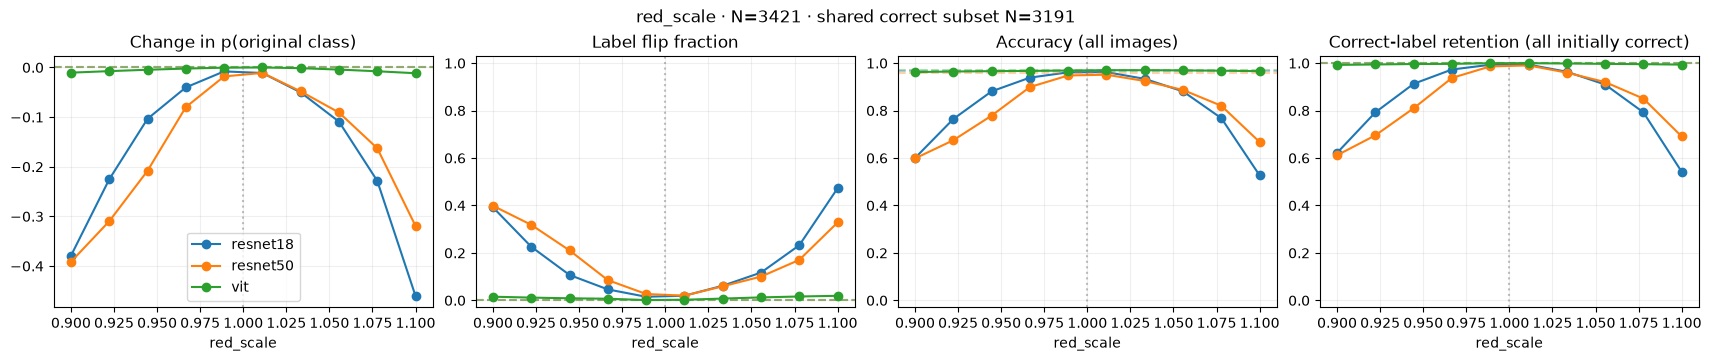

In [14]:
plot_stability('red_scale', levels['red_scale'])

Red scaling changes 16.9% and 17.2% of the two CNNs’ decisions, but only 1.0% of ViT decisions. The two CNNs are similar here despite differing substantially under rotation and green scaling. Model ranking therefore depends on the intervention; a single overall robustness score would conceal these different failure profiles.

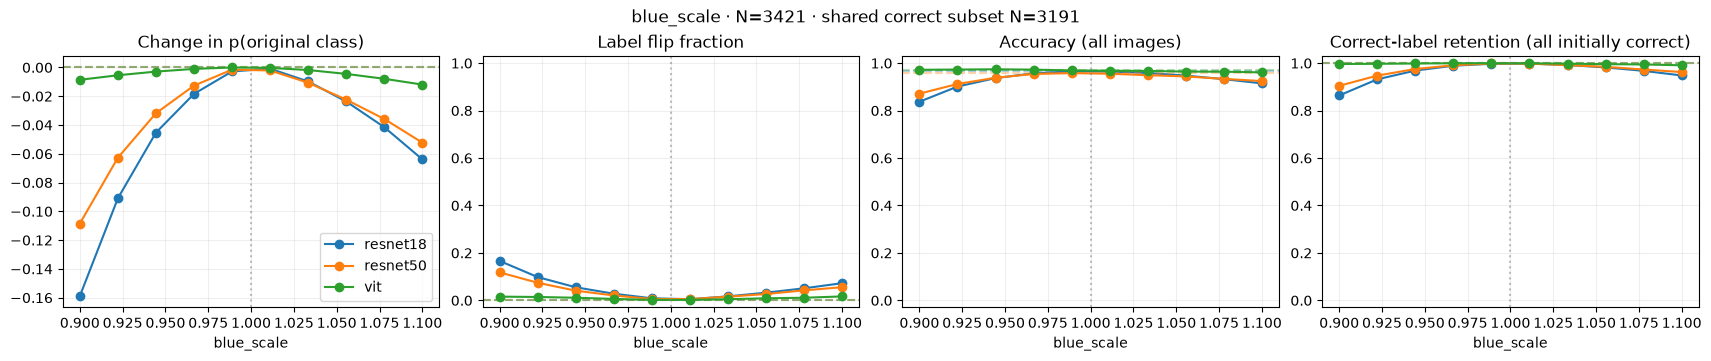

In [15]:
plot_stability('blue_scale', levels['blue_scale'])

Blue scaling changes 5.3% of ResNet18 and 4.1% of ResNet50 decisions, substantially less than red or green scaling over the same factor interval. The channel responses therefore constrain the color-sensitivity hypothesis: it is not a generic effect of multiplying any RGB channel. These comparisons concern raw channel interventions, not independently controlled staining components.

## Conditional correctness transitions — normalize by the initially correct or initially wrong group; average noise repeats within images

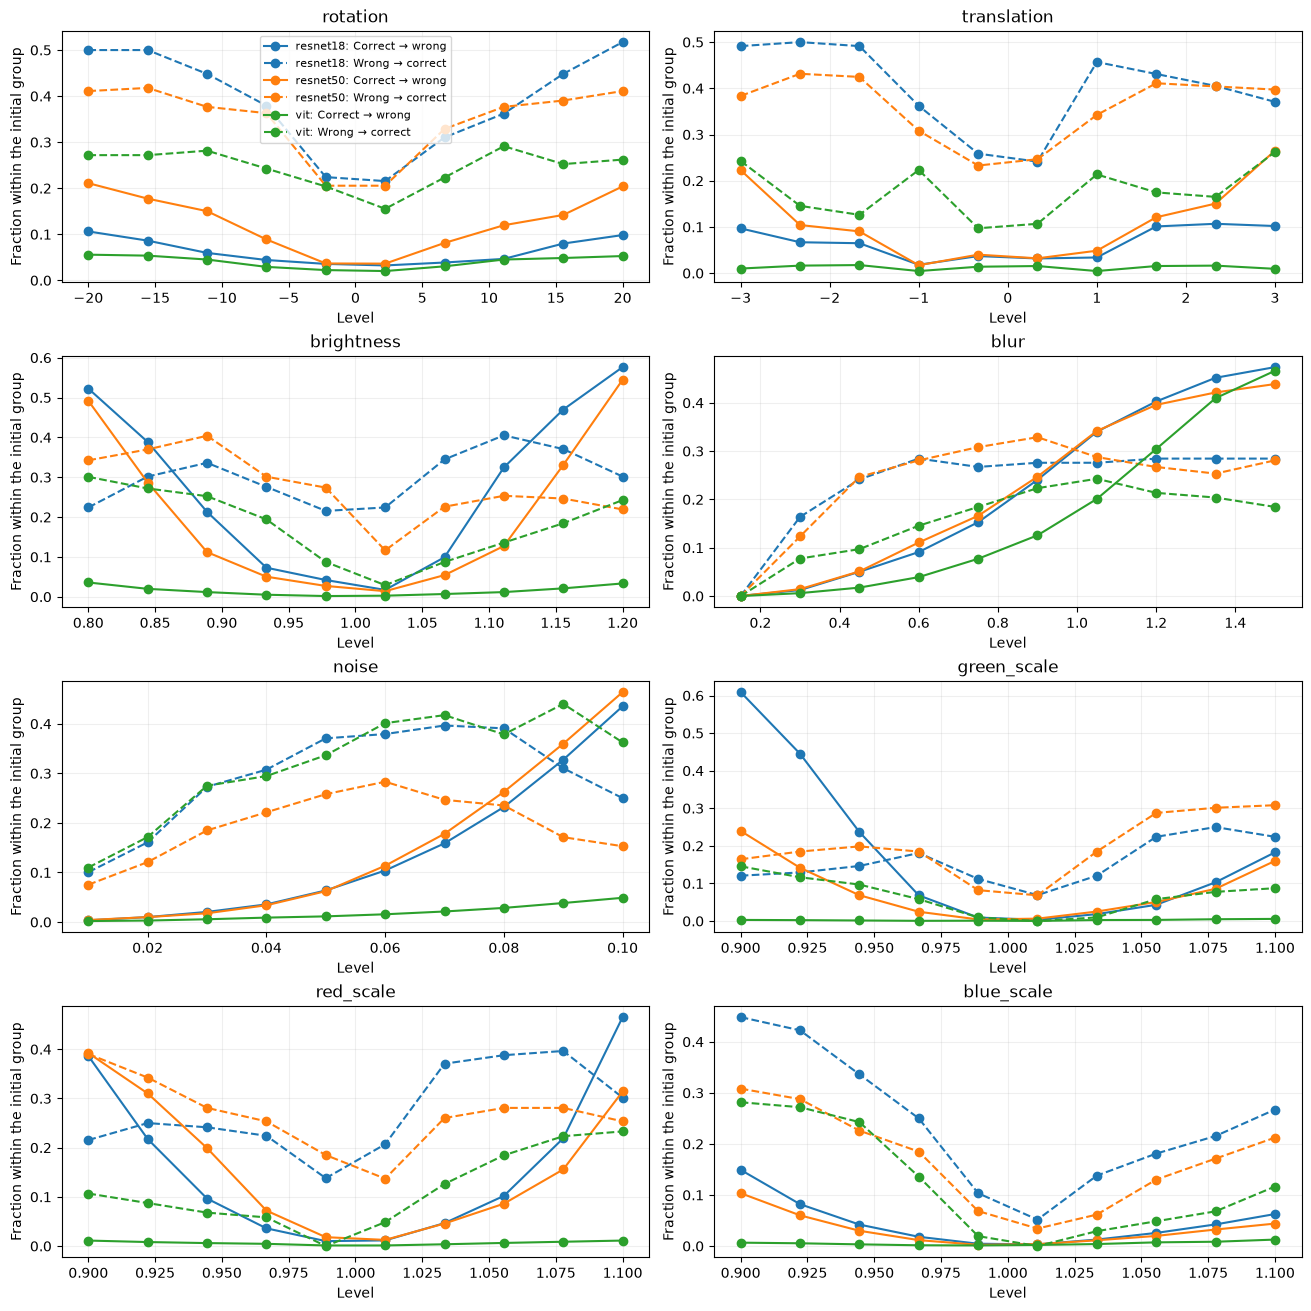

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
for ax, (kind, values) in zip(axes.flat, levels.items()):
    for m, name in enumerate(model_names):
        for title, style in [('Correct → wrong', '-'), ('Wrong → correct', '--')]:
            initial_accuracy = (base_class[m] == labels).mean()
            denominator = initial_accuracy if title == 'Correct → wrong' else 1 - initial_accuracy
            rate = metrics[kind][title][m].mean(-1) / denominator if denominator else np.full(len(values), np.nan)
            ax.plot(values, rate, style,
                    color=f'C{m}', marker='o', label=f'{name}: {title}')
    ax.set(title=kind, xlabel='Level', ylabel='Fraction within the initial group')
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.show()

Under rotation, ResNet18 becomes wrong on 6.3% of initially correct images, while 39.1% of initially wrong images switch to the true class. The latter is a lower bound on label changes among original errors because switches between two wrong classes are not counted. The conditional comparison reveals different responses of the two starting states, whereas overall accuracy is dominated by the much larger initially-correct group: 3,305 versus 116 images.

## 2B — Class-specific responses: equal weight per level, grouped by true class; stability is not accuracy

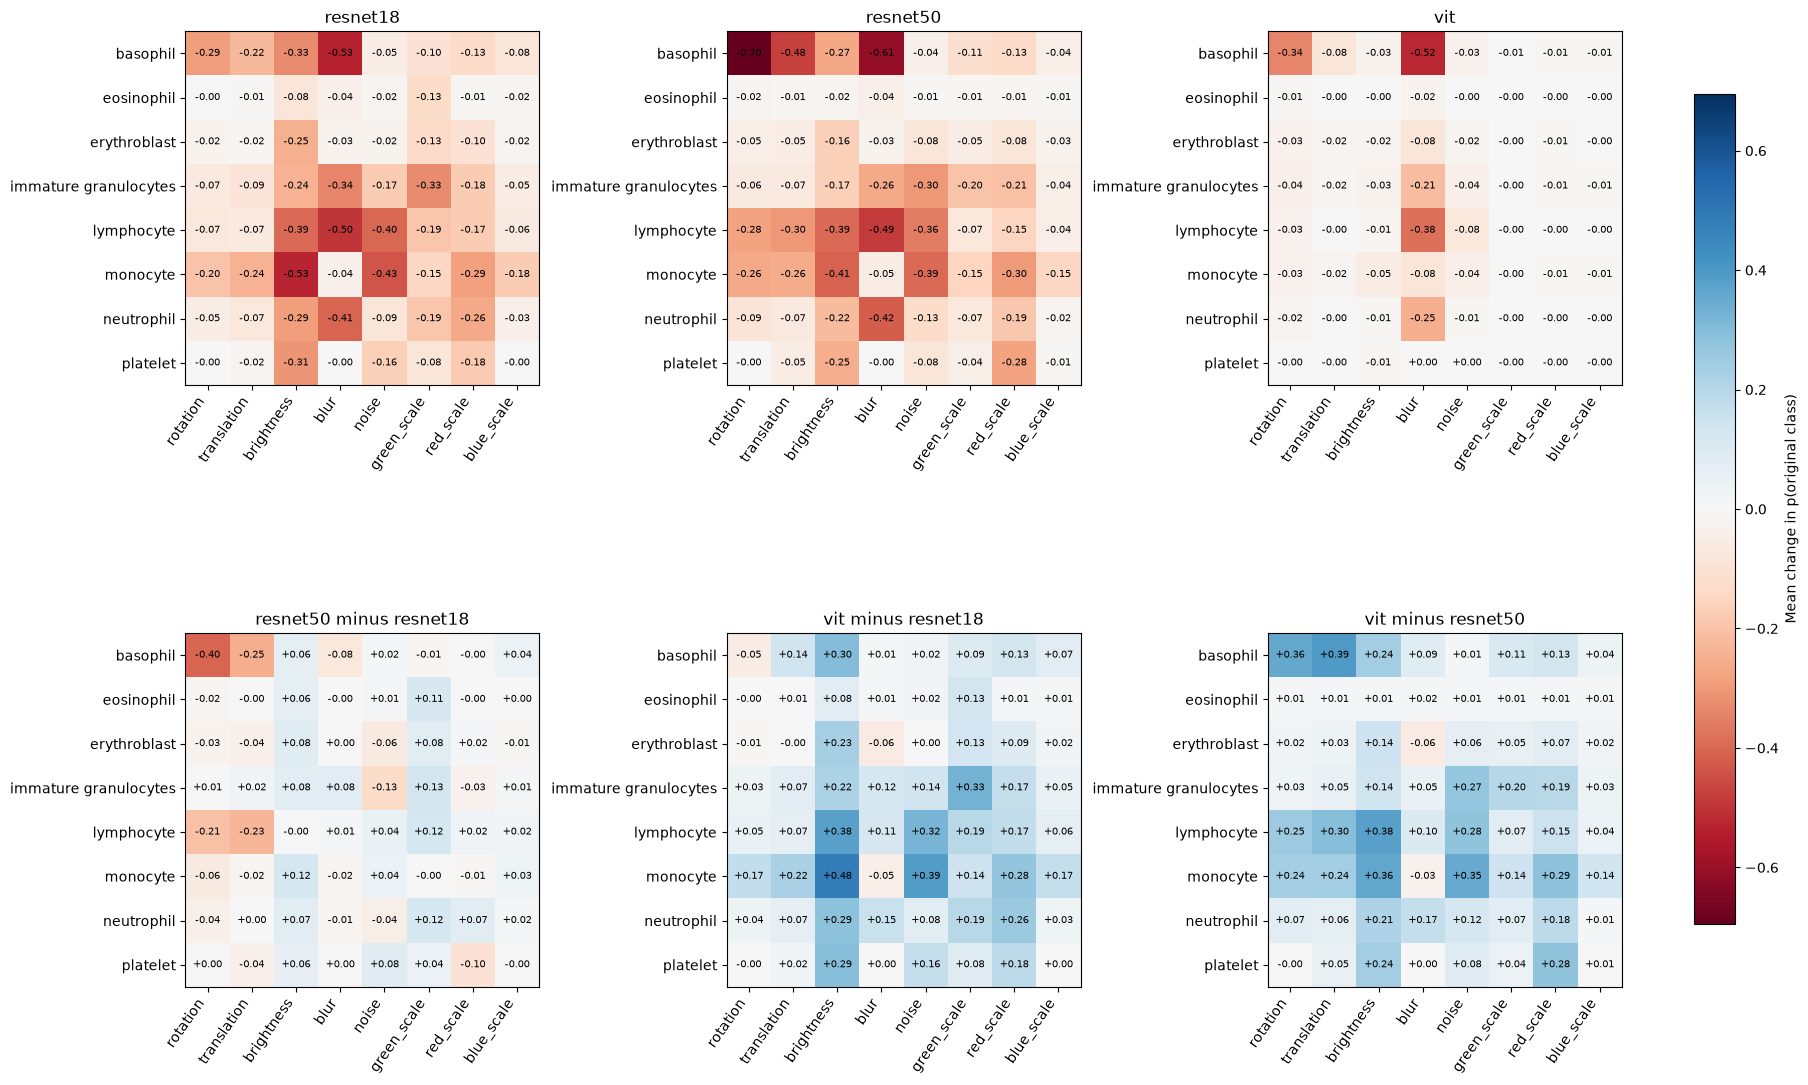

In [17]:
fingerprints = np.stack([np.array([
    metrics[kind]['Change in p(original class)'][m][:, labels == c].mean()
    for c in range(8) for kind in levels]).reshape(8, 8) for m in range(len(model_names))])
matrices = [*fingerprints, *[fingerprints[j] - fingerprints[i] for i, j in pairs]]
titles = [*model_names, *[f'{model_names[j]} minus {model_names[i]}' for i, j in pairs]]
scale = max(np.abs(matrices).max(), 0.01)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), layout='constrained')
for ax, matrix, title in zip(axes.flat, matrices, titles):
    im = ax.imshow(matrix, cmap='RdBu', vmin=-scale, vmax=scale)
    ax.set(title=title, xticks=range(8), xticklabels=list(levels), yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=55, ha='right')
    for c in range(8):
        for j in range(8):
            ax.text(j, c, f'{matrix[c, j]:+.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.7, label='Mean change in p(original class)')
plt.show()


ResNet50 loses about 0.70 original-class probability for basophils under rotation, while monocytes show the largest CNN brightness losses: 0.53 for ResNet18 and 0.41 for ResNet50. Under blur, basophils lose much more support than erythroblasts, and platelet decisions barely change. The model-level averages therefore combine distinct class-dependent responses rather than one common degradation mechanism.

## 2C — Selected examples of translation, brightness and blur; one largest-drop image per operation, not representative samples

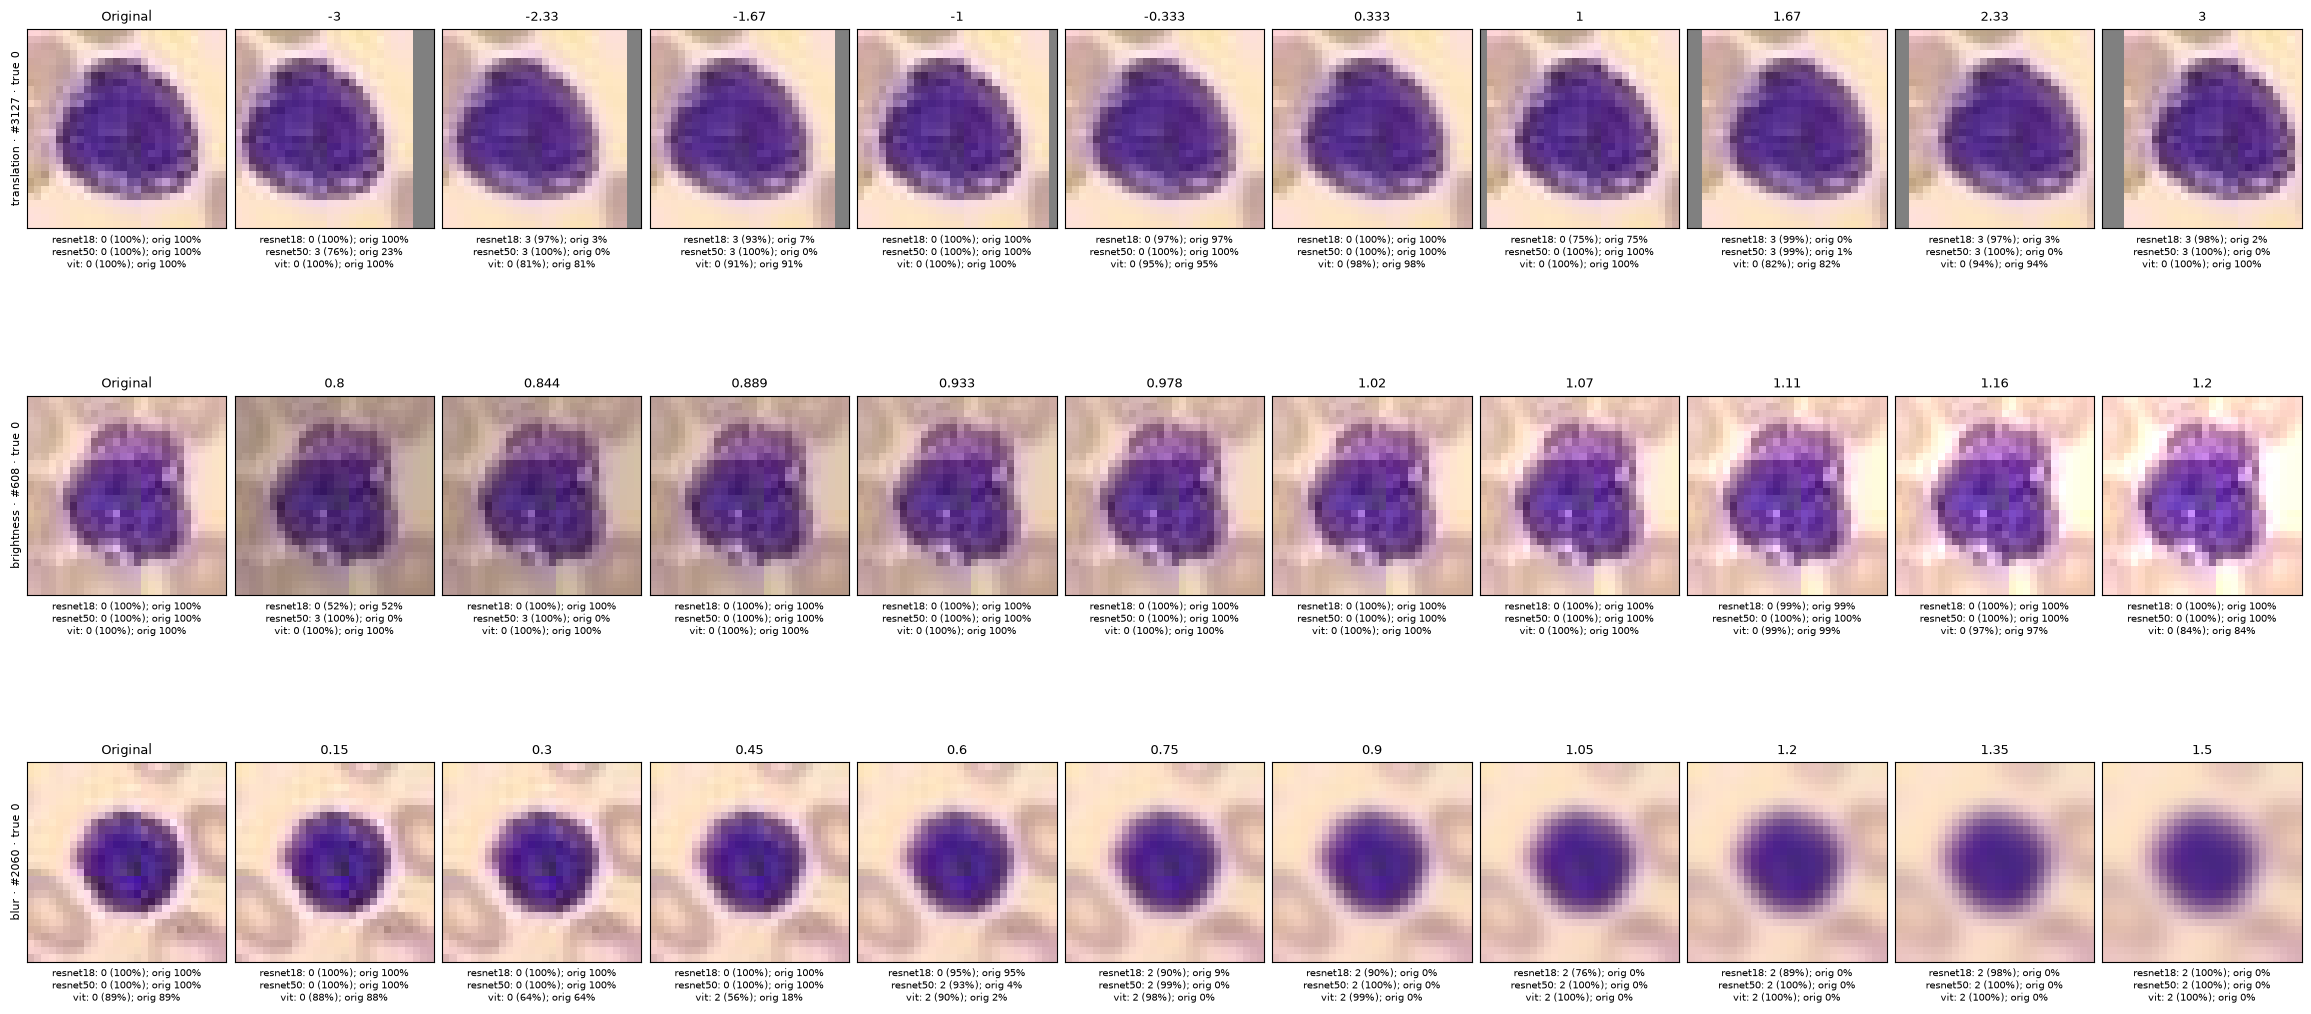

In [18]:
cases = ['translation', 'brightness', 'blur']
fig, axes = plt.subplots(len(cases), 11, figsize=(23, 11), layout='constrained')
for row, kind in enumerate(cases):
    values = levels[kind]
    p0 = np.take_along_axis(probabilities[kind][:, :, 0], base_class[:, None, :, None], axis=-1)[..., 0]
    pos = (base_probability[:, None, :] - p0).max(axis=(0, 1)).argmax()
    for col in range(11):
        ax = axes[row, col]
        ax.imshow(images[pos] if col == 0 else transform(images[pos:pos + 1], kind, values[col - 1])[0])
        p = baseline[:, pos] if col == 0 else probabilities[kind][:, col - 1, 0, pos]
        details = [f'{name}: {p[m].argmax()} ({p[m].max():.0%}); orig {p[m, base_class[m, pos]]:.0%}'
                   for m, name in enumerate(model_names)]
        ax.set_title('Original' if col == 0 else f'{values[col - 1]:.3g}', fontsize=9)
        ax.set_xlabel('\n'.join(details), fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(f'{kind} · #{indices[pos]} · true {labels[pos]}', fontsize=8)
plt.show()

For translation of image #3127, ResNet18 returns to basophil after switching to immature granulocyte, then switches again in the opposite shift direction. The response is not monotonic in shift magnitude, so endpoint-only testing would miss part of the decision sequence. Under blur, all three models assign image #2060 to erythroblast; this is a selected basophil example, not an estimate of how often that transition occurs.